<div style="background:#003CA3;color:white;padding:26px 30px;border-radius:14px;margin-bottom:18px">
<div style="color:#92DBDC;letter-spacing:.1em;font-weight:1000">SISTEMAS DE BIG DATA · SESIÓN 6</div>
<h1 style="color:white;margin:5px 0 10px">Calidad, coste y arquitectura</h1>
<p style="margin:0;font-size:17px">¿qué solución permite obtener resultados útiles, a tiempo y con un coste asumible?</p>
</div>


Al terminar podrás:
- explicar cinco dimensiones de calidad del dato
- distinguir la calidad de los datos de la del análisis
- estimar costes comparables; explicar el escalado vertical y horizontal
- y defender una selección tecnológica mediante una matriz ponderada y un análisis de sensibilidad.

***Caso conductor:*** VentasSur recibe pedidos de tiendas y de su web. Necesita un informe diario de ventas y quiere crecer.  
Una solución rápida con datos duplicados puede tomar decisiones equivocadas; **una solución excelente pero inasumible tampoco sirve**.

Todos los datos, precios y prestaciones de este cuaderno son **sintéticos y didácticos**, no tarifas ni mediciones de productos reales.  
Las simulaciones se ejecutan en un ordenador convencional: no se despliega un clúster ni se procesa Big Data real.

## Cómo utilizar este cuaderno
1. Abre el archivo en JupyterLab o en VS Code con las extensiones Python y Jupyter y selecciona un intérprete de Python.
2. Ejecuta las celdas desde arriba con **Mayús + Intro**. Si aparece `ModuleNotFoundError`, ejecuta la celda de instalación opcional y reinicia el kernel.
3. Las celdas **EXPERIMENTA** contienen decisiones que puedes modificar. Predice el resultado antes de ejecutarlas y anota qué observas.
4. Si no aparecen los controles deslizantes, modifica las variables: todos los experimentos esenciales funcionan sin widgets.
5. Antes de entregar, usa **Reiniciar kernel y ejecutar todo** y guarda tu copia con tus respuestas.

Una celda *Markdown* contiene explicaciones; una celda *Code* ejecuta Python. Una variable guarda un valor; una función reúne instrucciones reutilizables; un `DataFrame` es una tabla de filas y columnas. Los comentarios que empiezan por `#` explican código y no se ejecutan.

Ruta sugerida para 120 minutos: conceptos y preparación (15), calidad del dato (25), calidad analítica (15), costes (20), escalabilidad (15), matriz y discusión (30). Las ampliaciones se pueden completar fuera del aula.

In [ ]:
# OPCIONAL: quita el # inicial y ejecuta SOLO si faltan dependencias. Probablemente te falte 'ipywidgets'
%pip install numpy pandas matplotlib ipywidgets  
# %pip instala en el entorno del kernel del cuaderno; no es código Python ordinario.

In [3]:
import numpy as np                    # Cálculo numérico y generación de datos.
import pandas as pd                   # Tablas y operaciones sobre columnas.
import matplotlib.pyplot as plt       # Gráficos.
from IPython.display import display   # Presentación de tablas en el cuaderno.

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
AZUL = '#1458CC'
TURQUESA = '#92DBDC'
pd.set_option('display.max_columns', 12)
print('Entorno listo. Datos sintéticos y unidades monetarias en euros simulados.')

Entorno listo. Datos sintéticos y unidades monetarias en euros simulados.


## 1. Qué es una arquitectura y cómo se selecciona
Una **arquitectura de datos** es la organización de los componentes y de sus conexiones: de dónde llegan los datos, dónde se guardan, cómo se transforman y cómo se consultan. No es solo elegir una marca o una base de datos.

En VentasSur: **tiendas/web → recepción de pedidos → almacenamiento → validación y transformación → informe → decisión de compra**.  
Cada paso necesita reglas, responsables y seguimiento.

1) **Almacenamiento:** conserva información. No confundir capacidad (GB que caben) con velocidad de lectura.
2) **Procesamiento:** realiza trabajo sobre los datos: filtrar, agregar o entrenar un modelo.
3) **Comunicaciones:** mueve datos entre componentes, sedes o proveedores.
4) **Mantenimiento:** actualiza, supervisa, recupera fallos y mantiene las reglas y los permisos.
5) **Lotes o batch:** agrupa datos y los procesa periódicamente. Es razonable para un informe de mañana.
6) **Flujo o streaming:** procesa eventos conforme llegan. Puede ser necesario para alertas en segundos, a costa de mayor complejidad.

| Alternativa conceptual | Organización | Ventaja posible | Coste o limitación que investigar |
|---|---|---|---|
| Servidor único | Un equipo guarda y procesa | Sencillez de operación | Límite del equipo y riesgo de punto único de fallo |
| Clúster autogestionado | Varios nodos coordinados por el equipo técnico | Reparto de trabajo y capacidad | Red, coordinación y administración |
| Servicio gestionado | Un proveedor opera parte de la plataforma | Reduce algunas tareas de infraestructura | Tarifas por uso, salida de datos y dependencia del proveedor |

Estas categorías no son excluyentes: un servicio gestionado puede utilizar un clúster. **Distribuido** describe organización; **nube/local** describe ubicación o provisión; **gestionado** describe reparto de responsabilidades.

### Seleccionar según la necesidad
Primero define el resultado de negocio y los requisitos: volumen actual y futuro, plazo del informe, disponibilidad, calidad mínima, personal disponible y presupuesto. Después compara alternativas capaces de cumplirlos. No hace falta distribuir un problema que cabe holgadamente en una máquina.

Una arquitectura ayuda a controlar la calidad mediante validaciones, trazabilidad y recuperación, pero **no garantiza datos exactos**. Copiar un importe equivocado a diez servidores no lo corrige. La calidad, el coste y el tiempo se relacionan: validar y conservar históricos consume recursos; omitir controles puede elevar el coste de las decisiones erróneas.

## 2. Cinco dimensiones de calidad del dato
La calidad significa que los datos son adecuados **para un uso definido**. Antes de medir, debemos decidir qué columnas son obligatorias, qué representa una fila y qué reglas se aplican.

| Dimensión | Pregunta sencilla | Ejemplo y medida de este laboratorio |
|---|---|---|
| *Completitud* | ¿Está lo que necesito? | Porcentaje de celdas no ausentes en columnas obligatorias |
| *Consistencia* | ¿Los valores respetan las relaciones acordadas? | Porcentaje de filas evaluables con importe = unidades × precio |
| *Exactitud* | ¿Coincide con la realidad? | Porcentaje de importes observados a ±0,01 € de una fuente de referencia |
| *Actualidad* | ¿Los datos llegan a tiempo para su uso? | Porcentaje de pedidos recibidos en un máximo de 24 horas |
| *Unicidad* | ¿Hay una sola representación por entidad o evento? | Porcentaje de filas que no son repeticiones adicionales del identificador de pedido |

**Distinciones importantes:**
- Un importe puede cumplir la fórmula y ser incorrecto porque el precio es equivocado: **consistencia no implica exactitud**.
- La exactitud requiere una referencia fiable o comprobación externa. Aquí conocemos la verdad porque generamos los datos. En producción, una muestra auditada tiene incertidumbre.
- Una venta antigua no está necesariamente desactualizada. Aquí medimos el retraso entre el evento y su recepción, no la edad de una venta histórica.
- Dos compras del mismo cliente no son duplicados si son pedidos diferentes. La clave es `pedido_id`, no el cliente.
- Completitud de celdas no detecta pedidos enteros que nunca llegaron. Hace falta conciliación con la fuente para medir cobertura de eventos.
- No hay una media universal de calidad. Un fallo crítico puede invalidar el conjunto aunque la media sea alta.

Cuando una regla no se puede evaluar por datos ausentes, informaremos **su cobertura**.  
Un 100 % de consistencia en el 10 % de las filas no equivale a un 100 % en todas.

In [4]:
def generar_pedidos(n=1000, semilla=6):
    """Crea una tabla de referencia sin errores, con una fila por pedido."""
    rng = np.random.default_rng(semilla)  # Semilla: permite repetir el experimento.
    unidades = rng.integers(1, 8, size=n) # Límite superior excluido: valores 1 a 7.
    precio = rng.choice([10., 20., 40., 80.], size=n)
    fecha = pd.Timestamp('2026-01-01') + pd.to_timedelta(
        rng.integers(0, 30 * 24, size=n), unit='h')
    return pd.DataFrame({'pedido_id': np.arange(n), 'unidades': unidades,
                         'precio': precio, 'importe': unidades * precio,
                         'evento': fecha, 'recepcion': fecha + pd.Timedelta(hours=1)})

verdad = generar_pedidos()
display(verdad.head())
print('Total real del periodo:', verdad['importe'].sum(), '€')

,pedido_id,unidades,precio,importe,evento,recepcion
0,0,4,80.0,320.0,2026-01-15 13:00:00,2026-01-15 14:00:00
1,1,4,20.0,80.0,2026-01-25 00:00:00,2026-01-25 01:00:00
2,2,4,40.0,160.0,2026-01-15 11:00:00,2026-01-15 12:00:00
3,3,3,40.0,120.0,2026-01-16 04:00:00,2026-01-16 05:00:00
4,4,7,20.0,140.0,2026-01-28 01:00:00,2026-01-28 02:00:00


Total real del periodo: 152780.0 €


In [5]:
def deteriorar_datos(base, ausencia=0.10, error=0.10, duplicados=0.10,
                     retraso=0.10, semilla=42):
    """Introduce problemas controlados sin cambiar la tabla original.

    Los errores afectan a los pedidos de mayor importe: no son aleatorios.
    Las ausencias, en cambio, se seleccionan al azar entre los pedidos.
    """
    tasas = [ausencia, error, duplicados, retraso]
    if any(not 0 <= t <= 1 for t in tasas):
        raise ValueError('Las proporciones deben estar entre 0 y 1.')
    rng = np.random.default_rng(semilla)
    df = base.copy()  # Evita modificar el original por accidente.
    n = len(df)
    caros = df.nlargest(int(n * error), 'importe').index
    df.loc[caros, 'importe'] *= 1.5  # .loc selecciona filas y columnas por etiqueta.
    faltan = rng.choice(df.index, size=int(n * ausencia), replace=False)
    df.loc[faltan, 'importe'] = np.nan  # NaN representa un valor ausente.
    tarde = rng.choice(df.index, size=int(n * retraso), replace=False)
    df.loc[tarde, 'recepcion'] = df.loc[tarde, 'evento'] + pd.Timedelta(hours=72)
    # Duplicamos los pedidos caros: una selección sesgada afecta mucho al total.
    copias = df.nlargest(int(n * duplicados), 'precio')
    return pd.concat([df, copias], ignore_index=True)

# EXPERIMENTA: cambia una tasa cada vez, conservando las demás en cero.
AUSENCIA = 0.10
ERROR = 0.10
DUPLICADOS = 0.10
RETRASO = 0.10
observados = deteriorar_datos(verdad, AUSENCIA, ERROR, DUPLICADOS, RETRASO)
display(observados.head())
print('Filas recibidas:', len(observados), '| pedidos reales:', len(verdad))

,pedido_id,unidades,precio,importe,evento,recepcion
0,0,4,80.0,320.0,2026-01-15 13:00:00,2026-01-15 14:00:00
1,1,4,20.0,80.0,2026-01-25 00:00:00,2026-01-25 01:00:00
2,2,4,40.0,160.0,2026-01-15 11:00:00,2026-01-15 12:00:00
3,3,3,40.0,120.0,2026-01-16 04:00:00,2026-01-16 05:00:00
4,4,7,20.0,140.0,2026-01-28 01:00:00,2026-01-28 02:00:00


Filas recibidas: 1100 | pedidos reales: 1000


,Indicador (%),Cobertura de evaluación (%)
Completitud,98.44,100.00
Consistencia,85.86,90.64
Exactitud,85.86,90.64
Actualidad,90.18,100.00
Unicidad,90.91,100.00


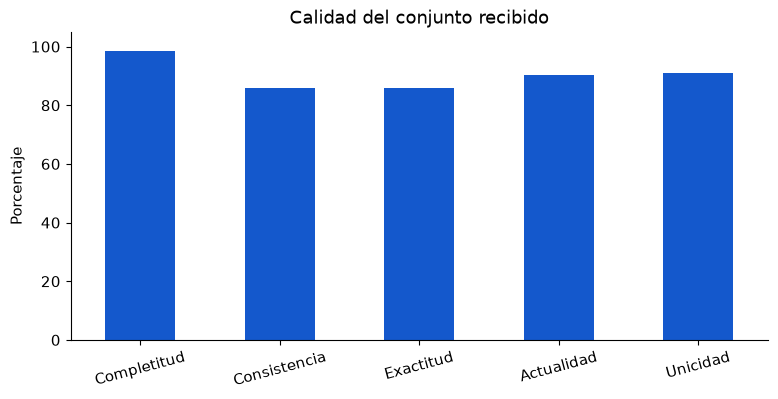

In [6]:
def medir_calidad(df, referencia, max_horas=24):
    """Devuelve porcentajes y coberturas; NaN significa regla no evaluable."""
    if len(df) == 0:
        raise ValueError('Se necesita al menos una fila.')
    requeridas = ['pedido_id', 'unidades', 'precio', 'importe', 'evento', 'recepcion']
    completas = df[requeridas].notna()
    evaluable = df[['unidades', 'precio', 'importe']].notna().all(axis=1)
    # isclose evita exigir igualdad binaria exacta a números decimales.
    coherente = np.isclose(df.loc[evaluable, 'importe'],
                          df.loc[evaluable, 'unidades'] * df.loc[evaluable, 'precio'],
                          atol=0.01, rtol=0)
    esperado = df['pedido_id'].map(referencia.set_index('pedido_id')['importe'])
    verificable = df['importe'].notna() & esperado.notna()
    exacto = np.isclose(df.loc[verificable, 'importe'], esperado[verificable],
                       atol=0.01, rtol=0)
    demora = (df['recepcion'] - df['evento']).dt.total_seconds() / 3600
    medible = demora.notna()
    a_tiempo = demora[medible].between(0, max_horas)
    def porcentaje(valores):
        return 100 * np.mean(valores) if len(valores) else np.nan
    return pd.DataFrame({
        'Indicador (%)': [100 * completas.to_numpy().mean(), porcentaje(coherente),
                          porcentaje(exacto), porcentaje(a_tiempo),
                          100 * (1 - df.duplicated('pedido_id').mean())],
        'Cobertura de evaluación (%)': [100, 100 * evaluable.mean(),
                                        100 * verificable.mean(), 100 * medible.mean(), 100]
    }, index=['Completitud', 'Consistencia', 'Exactitud', 'Actualidad', 'Unicidad'])

calidad = medir_calidad(observados, verdad)
display(calidad.round(2))
calidad['Indicador (%)'].plot.bar(color=AZUL, ylim=(0, 105), rot=15,
                                ylabel='Porcentaje', title='Calidad del conjunto recibido')
plt.show()

### Interpreta el denominador
La completitud de este ejemplo divide las celdas presentes entre **todas las celdas obligatorias**. Si falta el importe de 100 de 1.000 pedidos, pero las otras cinco columnas están completas, la completitud global es 98,33 %, aunque falte el importe en el 10 % de los pedidos. Conviene medir también por columna.

La unicidad usa `1 − repeticiones adicionales / filas recibidas`: con 1.000 pedidos y 100 copias es 90,91 %, no 90 %. Otra organización podría definirla de otra forma; hay que declarar el denominador. Las mediciones se hacen sobre las filas recibidas, por lo que los duplicados también pueden cambiar otros porcentajes.

**EXPERIMENTA:** prueba primero todas las tasas en cero; luego 30 % de ausencia; después 30 % de duplicados. Reejecuta las dos celdas anteriores. ¿Qué indicador cambia? ¿Por qué la completitud global puede ocultar un problema importante?

In [7]:
display((observados.notna().mean() * 100).rename('Completitud por columna (%)').round(2))
# Ejemplo independiente: importe y precio coherentes entre sí, pero ambos falsos.
falso = verdad.head(1).copy()
falso['precio'] *= 2
falso['importe'] *= 2
display(medir_calidad(falso, verdad).round(2))

pedido_id    100.00
unidades     100.00
precio       100.00
importe       90.64
evento       100.00
recepcion    100.00
Name: Completitud por columna (%), dtype: float64

,Indicador (%),Cobertura de evaluación (%)
Completitud,100.0,100.0
Consistencia,100.0,100.0
Exactitud,0.0,100.0
Actualidad,100.0,100.0
Unicidad,100.0,100.0


## 3. Calidad del resultado analítico
Un resultado analítico puede ser un total, una predicción, una clasificación o una recomendación. Su calidad depende de los datos, del método, de la evaluación y de si responde a la pregunta adecuada.

Para el informe de ventas usaremos **error relativo del total**:

$$E=100\,\frac{|\text{total estimado}-\text{total real}|}{\text{total real}}.$$

Un error de 5 % significa una diferencia de 5 € por cada 100 € reales. No es una medida universal: un total correcto puede esconder errores que se compensan entre tiendas. También importan el desglose por grupos, el plazo de entrega, la trazabilidad y la comprensión del informe.

| Aspecto | Qué comprobar |
|---|---|
| Adecuación | ¿El indicador responde a la decisión de negocio? |
| Error | ¿Se parece a una referencia comprobable? |
| Sesgo | ¿Falla más en un grupo, tienda o periodo? |
| Robustez | ¿Cambia mucho con pequeñas variaciones de datos o supuestos? |
| Reproducibilidad | ¿Se conocen datos, reglas, versiones y parámetros? |
| Oportunidad | ¿Está listo antes de tomar la decisión? |

Si fuera un modelo predictivo, habría que evaluar con datos no usados en su ajuste; para predicción temporal, respetando el orden del tiempo. La precisión medida con los mismos datos de entrenamiento puede ser engañosa. Un modelo que siempre dice «no fraude» parece acertar mucho si casi nunca hay fraude, pero puede ser inútil para detectarlo.

### Tres políticas de tratamiento
1. **Sin tratar:** sumar los importes observados. `sum()` omite ausencias, por lo que el resultado no representa necesariamente todas las ventas.
2. **Deduplicar y excluir ausencias:** evita contar copias, pero pierde ventas sin importe.
3. **Deduplicar y recalcular:** reconstruir importe a partir de unidades y precio. Solo es defendible si esas columnas son fiables y la regla de negocio es realmente esa. No sirve si hay descuentos o impuestos no representados.

La tercera política funciona en este mundo sintético por construcción; **no es una receta automática para datos reales**. En producción se conserva el original, se documentan las correcciones y se revisan los casos inciertos.

,Total estimado (€),Total real (€),Error relativo (%)
Sin tratar,208940.0,152780.0,36.76
Deduplicar y excluir,166020.0,152780.0,8.67
Deduplicar y recalcular,152780.0,152780.0,0.00


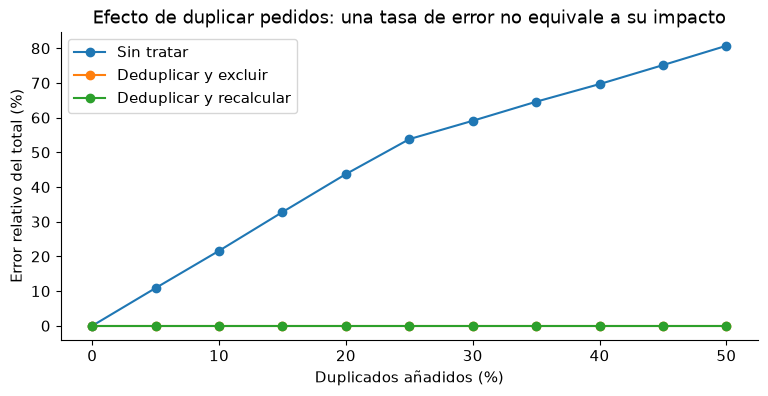

In [8]:
def comparar_informes(df, referencia):
    """Compara estrategias sobre el mismo periodo completo de ventas."""
    unicos = df.drop_duplicates('pedido_id', keep='first').copy()
    # keep='first' es válido aquí porque las copias son idénticas.
    # Si dos filas del mismo pedido discrepan, se necesita una regla de resolución.
    totales = pd.Series({
        'Sin tratar': df['importe'].sum(),
        'Deduplicar y excluir': unicos['importe'].dropna().sum(),
        'Deduplicar y recalcular': (unicos['unidades'] * unicos['precio']).sum()
    })
    real = referencia['importe'].sum()
    return pd.DataFrame({'Total estimado (€)': totales, 'Total real (€)': real,
                         'Error relativo (%)': 100 * abs(totales - real) / real})

display(comparar_informes(observados, verdad).round(2))

# Variamos un único problema para poder interpretar causa y efecto.
curva = []
for tasa in np.linspace(0, 0.5, 11):  # Once valores entre 0 y 0,5, ambos incluidos.
    df = deteriorar_datos(verdad, ausencia=0, error=0, duplicados=tasa, retraso=0)
    errores = comparar_informes(df, verdad)['Error relativo (%)']
    curva.append({'Duplicados añadidos (%)': tasa * 100, **errores.to_dict()})
pd.DataFrame(curva).set_index('Duplicados añadidos (%)').plot(marker='o')
plt.ylabel('Error relativo del total (%)')
plt.title('Efecto de duplicar pedidos: una tasa de error no equivale a su impacto')
plt.show()

In [ ]:
# EXPERIMENTA: ¿qué ventas están disponibles si el informe cierra 24 h después
# del fin del periodo? Aquí sí observamos el efecto de llegar tarde.
CIERRE = pd.Timestamp('2026-01-31') + pd.Timedelta(hours=24)
a_tiempo = observados.loc[observados['recepcion'] <= CIERRE]
display(comparar_informes(a_tiempo, verdad).round(2))
print('Pedidos todavía no recibidos:', len(verdad) - a_tiempo['pedido_id'].nunique())

### Tu explicación
Escribe aquí tus respuestas:
- ¿Puede un conjunto de datos completo producir un informe incorrecto? Usa una salida del cuaderno.
- ¿Por qué eliminar filas puede mejorar un porcentaje de calidad y empeorar el total de ventas?
- ¿Por qué recalcular no recupera pedidos que aún no han llegado?
- ¿Qué auditoría necesitarías antes de aplicar una corrección a ventas reales?

**Respuesta del alumno:** …

## 4. Costes: comparar el mismo trabajo y el mismo horizonte
El coste total de propiedad (**TCO**) reúne la inversión inicial y los gastos durante un periodo. Un precio por GB bajo no implica un sistema barato.

| Partida | Unidad de uso | Qué suele incluir o exigir revisar |
|---|---|---|
| Almacenamiento | GB-mes | Datos, réplicas, copias, índices y retención |
| Procesamiento | Horas de recurso o trabajo ejecutado | Transformaciones, consultas, reintentos y picos |
| Comunicaciones | GB transferidos | Salida de datos, movimientos entre sedes y zonas |
| Mantenimiento | Horas de personal/mes | Supervisión, actualizaciones, incidencias y evolución |
| Implantación | Euros iniciales | Migración, configuración, formación y pruebas |

También pueden existir licencias, energía, espacio, soporte, seguridad, impuestos y costes de interrupción. En un caso real se especifica qué está incluido y se evita contabilizar dos veces un mismo recurso.

Nuestro modelo compara un **mismo trabajo lógico** y usa:

$$C_m = V_m r p_{GB} + H_m p_h + S_m p_s + h_{personal}p_{personal}.$$
$$TCO_N = C_{inicial}+\sum_{m=1}^{N} C_m.$$

`V` es volumen lógico retenido en GB; `r`, copias equivalentes; `H`, horas facturables equivalentes; `S`, GB de salida. El volumen crece geométricamente: $V_m=V_1(1+g)^{m-1}$. Supone crecimiento neto después de aplicar retención. El mes 1 tiene exactamente el volumen indicado.

Para comparar plataformas no podemos suponer que una hora realiza el mismo trabajo en todas. Usamos un factor `rendimiento`: si vale 2, el mismo trabajo consume la mitad de horas equivalentes. Es una hipótesis didáctica que habría que sustituir por una prueba con la carga real.

Los precios de almacenamiento locales se interpretan aquí como coste equivalente de capacidad; no se vuelve a añadir la compra de esa misma capacidad. El coste inicial incluye solo implantación. **Este modelo no reproduce presupuestos comerciales** ni límites de capacidad, descuentos o mínimos facturables.

,gb_mes,hora_recurso,rendimiento,gb_salida,horas_personal,inicial
Servidor único,0.025,0.12,1.0,0.010,12,1200
Clúster propio,0.018,0.10,1.8,0.015,30,3000
Servicio gestionado,0.030,0.35,2.2,0.070,6,500


,Almacenamiento,Procesamiento,Comunicaciones,Mantenimiento,Implantación,Total
Arquitectura,,,,,,
Clúster propio,573.02,176.86,23.88,10800.0,3000.0,14573.75
Servicio gestionado,955.03,506.45,111.42,2160.0,500.0,4232.90
Servidor único,795.86,382.01,15.92,4320.0,1200.0,6713.78


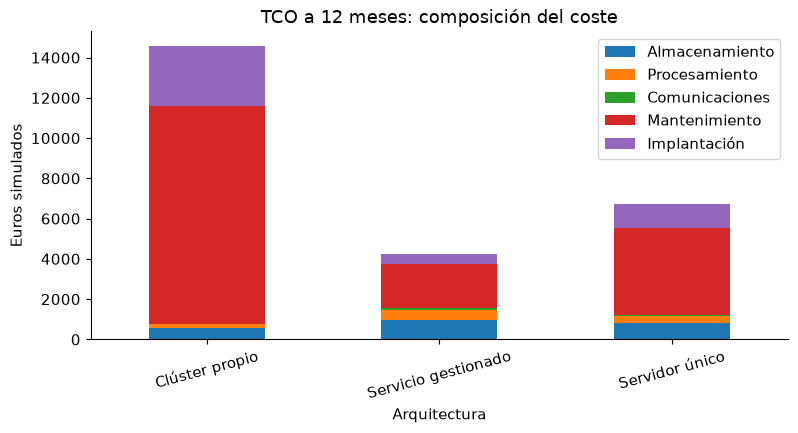

In [9]:
# Todos los valores son editables y simulados, no tarifas comerciales.
precios = pd.DataFrame({
    'gb_mes': [0.025, 0.018, 0.030],
    'hora_recurso': [0.12, 0.10, 0.35],
    'rendimiento': [1.0, 1.8, 2.2],
    'gb_salida': [0.01, 0.015, 0.07],
    'horas_personal': [12, 30, 6],
    'inicial': [1200, 3000, 500]
}, index=['Servidor único', 'Clúster propio', 'Servicio gestionado'])
display(precios)

def costes(meses=12, gb_inicial=1000, crecimiento=0.05, copias=2,
           horas_base=200, fraccion_salida=0.10, euro_personal=30, tarifas=None):
    """Calcula partidas por arquitectura y mes, con unidades homogéneas."""
    if meses < 1 or gb_inicial <= 0 or crecimiento < 0 or copias < 1:
        raise ValueError('Revisa meses, volumen, crecimiento y copias.')
    if min(horas_base, fraccion_salida, euro_personal) < 0:
        raise ValueError('Los usos y precios no pueden ser negativos.')
    tarifas = precios if tarifas is None else tarifas
    if (tarifas['rendimiento'] <= 0).any() or (tarifas < 0).any().any():
        raise ValueError('Tarifas no negativas y rendimiento positivo.')
    filas = []
    for nombre, p in tarifas.iterrows():  # Recorre las filas de la tabla de tarifas.
        for mes in range(1, meses + 1):
            factor = (1 + crecimiento) ** (mes - 1)
            volumen = gb_inicial * factor
            almacenamiento = volumen * copias * p['gb_mes']
            proceso = horas_base * factor / p['rendimiento'] * p['hora_recurso']
            red = volumen * fraccion_salida * p['gb_salida']
            personal = p['horas_personal'] * euro_personal
            inicial = p['inicial'] if mes == 1 else 0
            filas.append({'Arquitectura': nombre, 'Mes': mes, 'GB lógicos': volumen,
                          'Almacenamiento': almacenamiento, 'Procesamiento': proceso,
                          'Comunicaciones': red, 'Mantenimiento': personal,
                          'Implantación': inicial,
                          'Total': almacenamiento + proceso + red + personal + inicial})
    return pd.DataFrame(filas)

# EXPERIMENTA: cambia el plazo, crecimiento, retención implícita o salida de datos.
MESES = 12
CRECIMIENTO = 0.05
GB_INICIALES = 1000
COPIAS = 2
SALIDA = 0.10
coste_detalle = costes(MESES, GB_INICIALES, CRECIMIENTO, COPIAS,
                      fraccion_salida=SALIDA)
partidas = ['Almacenamiento', 'Procesamiento', 'Comunicaciones', 'Mantenimiento', 'Implantación']
resumen_costes = coste_detalle.groupby('Arquitectura')[partidas + ['Total']].sum()
display(resumen_costes.round(2))
resumen_costes[partidas].plot.bar(stacked=True, rot=15, ylabel='Euros simulados',
                                title=f'TCO a {MESES} meses: composición del coste')
plt.show()

### Predice, modifica, observa y explica
1. Duplica `COPIAS`. ¿Se duplica el TCO o solo una partida? Replicación no equivale a copia de seguridad: una eliminación puede propagarse a todas las réplicas.
2. Cambia `CRECIMIENTO` de 0 a 0,10. ¿Por qué el coste acumulado no crece linealmente con los meses?
3. Cambia `SALIDA` de 0,10 a 2: equivale a transferir fuera el doble del volumen retenido cada mes. Puede ocurrir al consultar o exportar repetidamente.
4. Reduce las horas de mantenimiento del clúster. ¿Estás aportando una mejora real de automatización o simplemente ocultando trabajo?

**Respuesta del alumno:** …

No es correcto concluir que el servicio más barato cumple la necesidad: falta comprobar capacidad, tiempo de respuesta y requisitos de calidad. La incertidumbre de las estimaciones también debe acompañar al presupuesto.

## 5. Escalabilidad vertical y horizontal
**Escalar** significa aumentar recursos para soportar más trabajo manteniendo el servicio aceptable.

| | Vertical: hacer mayor un equipo | Horizontal: añadir equipos |
|---|---|---|
| Ejemplo | Más RAM o CPU | Repartir datos entre cuatro nodos |
| Ventaja potencial | Menos cambios en la aplicación | Más capacidad agregada y reparto de carga |
| Límite | Tamaño máximo y coste del equipo | Coordinación, red y partes no paralelizables |
| Fallos | Puede seguir existiendo un punto único de fallo | Requiere replicación y recuperación diseñadas |
| No garantiza | Que el disco o la red dejen de limitar | Aceleración proporcional al número de nodos |

**Escalabilidad** es la capacidad de crecer; **elasticidad**, ajustar recursos a la demanda; **rendimiento**, cuánto trabajo se hace o cuánto se tarda con los recursos actuales. Latencia es tiempo de una respuesta; rendimiento de procesamiento o *throughput* es cantidad de trabajo por unidad de tiempo.

Si una parte del trabajo debe hacerse en secuencia, añadir nodos no la acelera. Usaremos una versión didáctica de la ley de Amdahl:

$$T(n)=T_1\left(s+\frac{1-s}{n}\right)+c(n-1).$$

`T1` son minutos con un nodo; `s`, fracción secuencial; `c`, minutos adicionales por nodo para coordinar. El modelo vertical usa $T(v)=T_1/v^{0,8}$: la potencia nominal crece, pero con rendimientos decrecientes. **Son modelos ilustrativos, no predicciones de una tecnología**. No incluyen colas, fallos, límites de RAM ni red real.

,Estrategia,Factor de recursos,Minutos,€/trabajo
0,Horizontal,1,120.00,0.80
1,Vertical,1,120.00,0.80
2,Horizontal,2,71.00,0.95
3,Vertical,2,68.92,1.13
4,Horizontal,4,49.50,1.32
5,Vertical,4,39.59,1.60
6,Horizontal,8,44.75,2.39
7,Vertical,8,22.74,2.26
8,Horizontal,16,54.38,5.80
9,Vertical,16,13.06,3.20


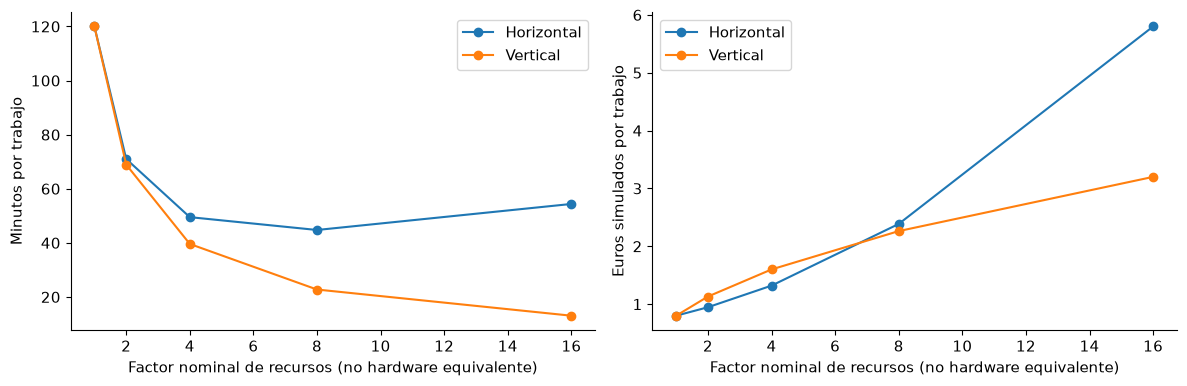

In [10]:
def simular_escalado(fraccion_secuencial=0.15, coordinacion=2., tiempo_base=120.):
    """Compara tiempo y coste por trabajo completo, no solo coste por hora."""
    if not 0 <= fraccion_secuencial <= 1 or coordinacion < 0 or tiempo_base <= 0:
        raise ValueError('Parámetros de escalado no válidos.')
    filas = []
    for n in [1, 2, 4, 8, 16]:
        horizontal = tiempo_base * (fraccion_secuencial + (1-fraccion_secuencial)/n) + coordinacion*(n-1)
        vertical = tiempo_base / n**0.8
        # Precios horarios ficticios: el equipo grande encarece más que linealmente.
        filas.append(['Horizontal', n, horizontal, horizontal/60 * n * 0.4])
        filas.append(['Vertical', n, vertical, vertical/60 * 0.4 * n**1.3])
    return pd.DataFrame(filas, columns=['Estrategia', 'Factor de recursos', 'Minutos', '€/trabajo'])

# EXPERIMENTA: 0,05 / 0,50 / 0,90 de trabajo secuencial; 0 / 2 / 8 de coordinación.
escalado = simular_escalado(fraccion_secuencial=0.15, coordinacion=2)
display(escalado.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nombre, grupo in escalado.groupby('Estrategia'):
    axes[0].plot(grupo['Factor de recursos'], grupo['Minutos'], 'o-', label=nombre)
    axes[1].plot(grupo['Factor de recursos'], grupo['€/trabajo'], 'o-', label=nombre)
for ax in axes:
    ax.set_xlabel('Factor nominal de recursos (no hardware equivalente)')
    ax.legend()
axes[0].set_ylabel('Minutos por trabajo')
axes[1].set_ylabel('Euros simulados por trabajo')
plt.tight_layout()
plt.show()

**Comprueba:** ¿puede pasar que 16 nodos tarden más que 8? ¿Y que una ejecución más rápida cueste más? Explica qué ocurre si el cuello de botella es una operación secuencial o el envío de datos por la red.

El coste por trabajo anterior incluye solo cómputo de ese trabajo; **no es el TCO** del apartado 4. Un sistema puede terminar pronto y seguir facturando recursos encendidos. No mezcles ambas medidas en una comparación.

## 6. Comparar con criterios técnicos y económicos
Una **matriz de decisión** documenta alternativas, criterios, medidas, preferencias y resultados. No sustituye al razonamiento: lo hace visible.

### Paso 1 · Separar requisitos obligatorios de preferencias
Un requisito obligatorio elimina alternativas que no lo cumplen. Ejemplo: un informe debe terminar en 60 minutos. Una opción que tarda 70 no se vuelve aceptable porque sea barata. Un criterio ponderable expresa una preferencia entre alternativas viables.

### Paso 2 · Medir y documentar
Usaremos un conjunto de prestaciones **supuestas para una prueba piloto**. La corrección analítica es `100 − error relativo del total`, acotada a 0–100 para la matriz; no es la exactitud del dato ni la accuracy de un clasificador. Una prestación así no se deduce del nombre de una arquitectura: procede del conjunto de controles, proceso y datos del piloto.

| Criterio | Preferencia | Evidencia necesaria en un caso real |
|---|---|---|
| TCO del horizonte | Menor | Presupuesto y consumos bajo la misma carga |
| Tiempo del informe | Menor | Prueba de extremo a extremo con carga representativa |
| Corrección analítica | Mayor | Comparación contra muestra o total auditado |
| Margen de crecimiento | Mayor | Volumen máximo soportado / volumen de referencia bajo el mismo plazo |
| Facilidad operativa | Mayor | Rúbrica según tareas y competencias del equipo |

Rúbrica de facilidad: **1** = operación manual especializada; **3** = automatización parcial y formación habitual; **5** = tareas rutinarias muy automatizadas y equipo preparado. Los valores 2 y 4 son intermedios y requieren explicación. Esta rúbrica es contextual, no una verdad universal.

### Paso 3 · Llevar todas las medidas a una escala comparable
Con referencias fijas inferior `L` y superior `U`:

- Mayor es mejor: $p=100\,(x-L)/(U-L)$.
- Menor es mejor: $p=100\,(U-x)/(U-L)$.

Acotamos el resultado entre 0 y 100. Para coste, 0 € recibe 100 puntos y 30.000 € recibe 0; para tiempo, 0 minutos recibe 100 y 120 recibe 0. Son anclas didácticas, no metas universales. El recorte pierde distinción fuera del intervalo: si muchas opciones se saturan, revisa las anclas antes de decidir.

### Paso 4 · Ponderar
$P_i=\sum_j w_j p_{ij}$, con pesos no negativos que sumen 1. Dar peso 0,40 al coste significa que representa el 40 % de la puntuación. Un precio en euros **no puede sumarse directamente** a minutos o porcentajes.

Evita contar varias veces la misma ventaja: mantenimiento ya está en el TCO; facilidad operativa aquí debe representar competencias, continuidad y dificultad de operar, no volver a sumar las mismas horas de personal. Los pesos son juicios del equipo y deben acordarse antes de mirar quién gana.

,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5)
Servidor único,6713.78,70,96,1.5,4
Clúster propio,14573.75,35,98,6.0,2
Servicio gestionado,4232.90,25,99,10.0,5


,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5)
Servidor único,77.62,41.67,60.0,5.56,75.0
Clúster propio,51.42,70.83,80.0,55.56,25.0
Servicio gestionado,85.89,79.17,90.0,100.00,100.0


,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5),Puntuación,Viable,Incumple
Servicio gestionado,4232.90,25,99,10.0,5,89.10,True,
Clúster propio,14573.75,35,98,6.0,2,60.43,True,
Servidor único,6713.78,70,96,1.5,4,54.95,False,"Plazo, Calidad, Crecimiento"


Mejor puntuación entre las viables: Servicio gestionado


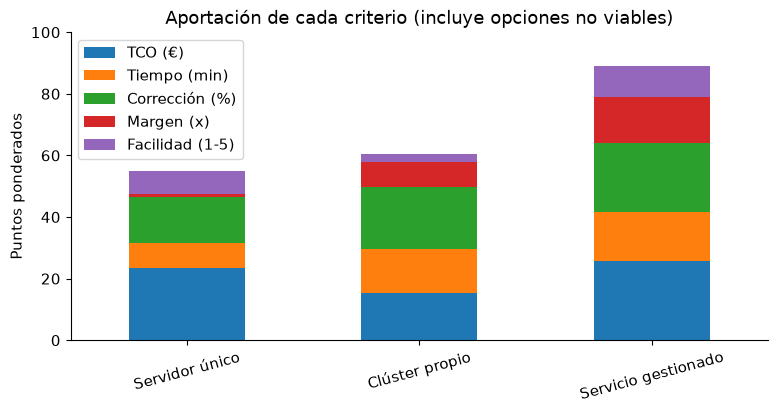

In [11]:
# El TCO procede de tu escenario del apartado 4; las prestaciones son supuestos
# independientes de un piloto didáctico, no resultados del simulador de escalado.
alternativas = pd.DataFrame({
    'Tiempo (min)': [70, 35, 25],
    'Corrección (%)': [96, 98, 99],
    'Margen (x)': [1.5, 6, 10],
    'Facilidad (1-5)': [4, 2, 5]
}, index=precios.index)
alternativas['TCO (€)'] = resumen_costes['Total']  # pandas alinea por el nombre.
alternativas = alternativas[['TCO (€)', 'Tiempo (min)', 'Corrección (%)',
                             'Margen (x)', 'Facilidad (1-5)']]

# (mínimo de referencia, máximo de referencia, mayor_es_mejor)
escalas = {'TCO (€)': (0, 30000, False), 'Tiempo (min)': (0, 120, False),
           'Corrección (%)': (90, 100, True), 'Margen (x)': (1, 10, True),
           'Facilidad (1-5)': (1, 5, True)}
pesos = pd.Series({'TCO (€)': 0.30, 'Tiempo (min)': 0.20, 'Corrección (%)': 0.25,
                   'Margen (x)': 0.15, 'Facilidad (1-5)': 0.10})

def puntuar(tabla, ponderaciones):
    """Normaliza las unidades y suma contribuciones; no decide la viabilidad."""
    w = pd.Series(ponderaciones).reindex(tabla.columns)
    if w.isna().any() or (w < 0).any() or not np.isclose(w.sum(), 1):
        raise ValueError('Incluye todos los criterios y pesos no negativos que sumen 1.')
    if not np.isfinite(tabla.to_numpy(dtype=float)).all():
        raise ValueError('Completa todas las medidas con valores finitos.')
    puntos = pd.DataFrame(index=tabla.index)
    for criterio in tabla.columns:
        inferior, superior, mayor = escalas[criterio]
        proporcion = (tabla[criterio] - inferior) / (superior - inferior)
        puntos[criterio] = (100 * (proporcion if mayor else 1-proporcion)).clip(0, 100)
    contribuciones = puntos.mul(w, axis='columns')  # Multiplica cada columna por su peso.
    return puntos, contribuciones, contribuciones.sum(axis=1)

def evaluar(tabla, ponderaciones, presupuesto=15000, plazo=60, calidad_min=97, margen_min=2):
    """Aplica requisitos obligatorios y devuelve una clasificación trazable."""
    puntos, aportes, total = puntuar(tabla, ponderaciones)
    condiciones = pd.DataFrame({'Presupuesto': tabla['TCO (€)'] <= presupuesto,
                                'Plazo': tabla['Tiempo (min)'] <= plazo,
                                'Calidad': tabla['Corrección (%)'] >= calidad_min,
                                'Crecimiento': tabla['Margen (x)'] >= margen_min})
    resultado = tabla.copy()
    resultado['Puntuación'] = total
    resultado['Viable'] = condiciones.all(axis=1)
    resultado['Incumple'] = condiciones.apply(
        lambda fila: ', '.join(fila.index[~fila]), axis=1)
    # lambda es una función breve; ~ invierte True/False para encontrar fallos.
    return resultado.sort_values(['Viable', 'Puntuación'], ascending=[False, False]), puntos, aportes

# EXPERIMENTA: cambia pesos y requisitos y vuelve a ejecutar esta celda.
PRESUPUESTO = 15000
PLAZO = 60
CALIDAD_MIN = 97
MARGEN_MIN = 2
ranking, puntos, contribuciones = evaluar(alternativas, pesos, PRESUPUESTO,
                                        PLAZO, CALIDAD_MIN, MARGEN_MIN)
display(alternativas.round(2))
display(puntos.round(2))
display(ranking.round(2))
viables = ranking.loc[ranking['Viable']]
if viables.empty:
    print('Ninguna opción cumple: revisar diseño o requisitos; no forzar un ganador.')
else:
    mejor = viables['Puntuación'].max()
    empatadas = viables.index[np.isclose(viables['Puntuación'], mejor)].tolist()
    print('Mejor puntuación entre las viables:', ', '.join(empatadas))
contribuciones.plot.bar(stacked=True, ylim=(0, 100), rot=15,
                       ylabel='Puntos ponderados', title='Aportación de cada criterio (incluye opciones no viables)')
plt.show()

### 6.1 Sensibilidad: ¿es estable la recomendación?
Una clasificación depende de pesos, medidas, anclas y requisitos. Si un pequeño cambio altera la decisión, conviene investigar más o preferir una solución reversible. El análisis siguiente cambia el peso del coste y reparte el resto proporcionalmente a los otros pesos iniciales. Las prestaciones y los requisitos se mantienen.

Un ganador estable frente a los pesos **no** prueba estabilidad frente a errores del presupuesto. Por eso también probaremos aumentos de coste. Si cambias el horizonte del TCO, revisa presupuesto y anclas: no compares 36 meses con un límite que se había acordado para 12.

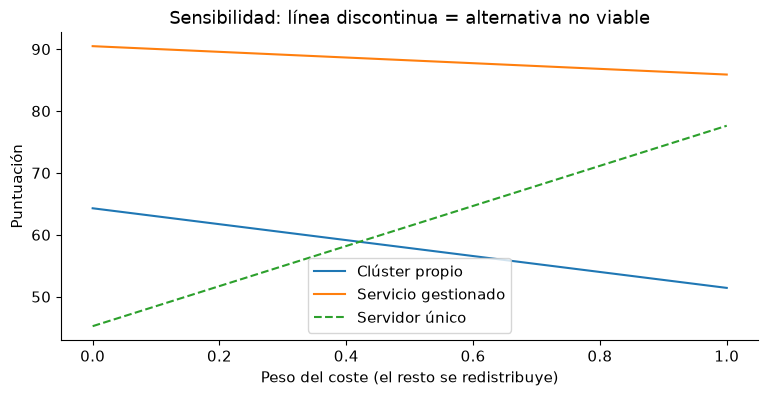

,Sobrecoste gestionado (%),Mejor opción viable
0,0.0,Servicio gestionado
1,20.0,Servicio gestionado
2,50.0,Servicio gestionado
3,100.0,Servicio gestionado


In [12]:
def pesos_con_coste(peso_coste, base):
    """Conserva las proporciones relativas de los criterios distintos del coste."""
    if not 0 <= peso_coste <= 1:
        raise ValueError('El peso del coste debe estar entre 0 y 1.')
    nuevos = base.copy().astype(float)
    otros = nuevos.index != 'TCO (€)'
    suma = nuevos.loc[otros].sum()
    if suma <= 0:
        raise ValueError('Debe existir algún peso no nulo fuera del coste.')
    nuevos.loc[otros] = nuevos.loc[otros] / suma * (1-peso_coste)
    nuevos['TCO (€)'] = peso_coste
    return nuevos

sensibilidad = []
for w in np.linspace(0, 1, 21):
    r, _, _ = evaluar(alternativas, pesos_con_coste(w, pesos), PRESUPUESTO,
                      PLAZO, CALIDAD_MIN, MARGEN_MIN)
    for nombre, fila in r.iterrows():
        sensibilidad.append({'Peso del coste': w, 'Arquitectura': nombre,
                              'Puntos': fila['Puntuación'], 'Viable': fila['Viable']})
sensibilidad = pd.DataFrame(sensibilidad)
for nombre, grupo in sensibilidad.groupby('Arquitectura'):
    estilo = '-' if grupo['Viable'].iloc[0] else '--'
    plt.plot(grupo['Peso del coste'], grupo['Puntos'], estilo, label=nombre)
plt.xlabel('Peso del coste (el resto se redistribuye)')
plt.ylabel('Puntuación')
plt.title('Sensibilidad: línea discontinua = alternativa no viable')
plt.legend()
plt.show()

# Escenario adverso: ¿qué ocurre si el TCO del servicio gestionado aumenta?
filas = []
for sobrecoste in [0, 0.20, 0.50, 1.0]:
    escenario = alternativas.copy()
    escenario.loc['Servicio gestionado', 'TCO (€)'] *= 1 + sobrecoste
    r, _, _ = evaluar(escenario, pesos, PRESUPUESTO, PLAZO, CALIDAD_MIN, MARGEN_MIN)
    elegibles = r.loc[r['Viable']]
    nombres = 'Ninguna'
    if not elegibles.empty:
        nombres = ', '.join(elegibles.index[np.isclose(elegibles['Puntuación'], elegibles['Puntuación'].max())])
    filas.append({'Sobrecoste gestionado (%)': 100*sobrecoste, 'Mejor opción viable': nombres})
display(pd.DataFrame(filas))

### 6.2 Panel interactivo opcional
El panel modifica la importancia del coste y el presupuesto. Pulsa y observa cómo cambian la viabilidad y la puntuación. **El panel no modifica las variables anteriores ni la actividad final**: es un experimento independiente con las alternativas ya calculadas. Si no aparece, usa `evaluar(...)` cambiando sus argumentos.

In [13]:
def panel_decision(peso_coste=0.30, presupuesto=15000):
    """Muestra una evaluación temporal sin modificar la matriz original."""
    w = pesos_con_coste(peso_coste, pesos)
    r, _, _ = evaluar(alternativas, w, presupuesto, PLAZO, CALIDAD_MIN, MARGEN_MIN)
    display(r[['TCO (€)', 'Puntuación', 'Viable', 'Incumple']].round(2))

try:
    import ipywidgets as widgets
    widgets.interact(panel_decision,
                     peso_coste=widgets.FloatSlider(value=0.30, min=0, max=1, step=0.05,
                                                    description='Peso coste', continuous_update=False),
                     presupuesto=widgets.IntSlider(value=15000, min=1000, max=40000, step=500,
                                                   description='Presupuesto', continuous_update=False))
except ImportError:
    print('Widgets no instalados. Cambia los argumentos de esta llamada:')
    panel_decision(peso_coste=0.30, presupuesto=15000)

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='Peso coste', max=1.0, step=…

## 7. Actividad final · Tu matriz de decisión tecnológica
**Encargo:** eres parte del equipo que propone la arquitectura de VentasSur. Entrega una matriz y una recomendación argumentada. El objetivo no es adivinar una tecnología favorita, sino justificar una decisión trazable.

### Escenario de partida
Se retiene inicialmente 1 TB lógico (1.000 GB en este modelo decimal), con crecimiento neto mensual del 5 %, dos copias equivalentes y un horizonte de 12 meses. El informe debe terminar en 60 minutos; la corrección analítica mínima del piloto es 97 %; el margen de crecimiento mínimo, 2 veces el volumen de referencia; el presupuesto total, 15.000 € simulados. Usa los precios y prestaciones del ejemplo como hipótesis de partida, y declara cualquier cambio.

### Trabajo que debes realizar
1. Describe la decisión de negocio y las tres alternativas sin limitarte a nombrar productos.
2. Define los cuatro requisitos obligatorios y explica por qué una puntuación no puede compensar su incumplimiento.
3. Calcula el TCO con las cuatro partidas recurrentes y la implantación. Mantén las mismas unidades, carga y horizonte.
4. Elige y justifica cinco pesos. Deben sumar 1. Explica las anclas de normalización y evita duplicidades entre criterios.
5. Completa la matriz con medidas originales, puntos normalizados, aportaciones y resultado. Identifica las opciones no viables y los posibles empates.
6. Haz dos escenarios: a) coste más importante; b) incremento del TCO gestionado del 50 %. Distingue cambios de puntuación de cambios de viabilidad.
7. Recomienda una alternativa, o argumenta que ninguna cumple. Indica qué prueba real necesitas antes de contratar y qué incertidumbre podría cambiar tu recomendación.

**Entrega:** este mismo cuaderno con las celdas siguientes cumplimentadas y ejecutadas, tres tablas de resultados y una conclusión de 150–250 palabras. No hace falta contratar servicios ni descargar datos.

In [16]:
# PLANTILLA DEL ALUMNO: este bloque vuelve a generar el escenario del encargo
# para no depender de los cambios experimentales de celdas anteriores.
mis_costes = costes(meses=12, gb_inicial=1000, crecimiento=0.05, copias=3,
                    horas_base=150, fraccion_salida=0.15, euro_personal=60)
mi_matriz = alternativas.copy()
mi_matriz['TCO (€)'] = mis_costes.groupby('Arquitectura')['Total'].sum()

# TODO: modifica estos pesos y justifícalos en la celda de texto posterior.
mis_pesos = pd.Series({'TCO (€)': 0.30, 'Tiempo (min)': 0.20,
                      'Corrección (%)': 0.25, 'Margen (x)': 0.15,
                      'Facilidad (1-5)': 0.10})
mis_requisitos = {'presupuesto': 3000000, 'plazo': 60, 'calidad_min': 97, 'margen_min': 2}
mi_resultado, mis_puntos, mis_aportes = evaluar(mi_matriz, mis_pesos, **mis_requisitos)
# ** expande el diccionario: cada clave se pasa como nombre de un argumento.
display(mi_matriz.round(2))
display(mis_puntos.round(2))
display(mis_aportes.round(2))
display(mi_resultado.round(2))

# Escenario A: mayor peso del coste, manteniendo el resto proporcional.
pesos_A = pesos_con_coste(0.60, mis_pesos)
resultado_A, _, _ = evaluar(mi_matriz, pesos_A, **mis_requisitos)
# Escenario B: incertidumbre económica, manteniendo los pesos originales.
matriz_B = mi_matriz.copy()
matriz_B.loc['Servicio gestionado', 'TCO (€)'] *= 1.50
resultado_B, _, _ = evaluar(matriz_B, mis_pesos, **mis_requisitos)
print('Escenario A: peso del coste = 60 %')
display(resultado_A.round(2))
print('Escenario B: TCO gestionado +50 %')
display(resultado_B.round(2))

,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5)
Servidor único,11344.17,70,96,1.5,4
Clúster propio,25627.98,35,98,6.0,2
Servicio gestionado,6799.51,25,99,10.0,5


,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5)
Servidor único,62.19,41.67,60.0,5.56,75.0
Clúster propio,14.57,70.83,80.0,55.56,25.0
Servicio gestionado,77.33,79.17,90.0,100.00,100.0


,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5)
Servidor único,18.66,8.33,15.0,0.83,7.5
Clúster propio,4.37,14.17,20.0,8.33,2.5
Servicio gestionado,23.20,15.83,22.5,15.00,10.0


,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5),Puntuación,Viable,Incumple
Servicio gestionado,6799.51,25,99,10.0,5,86.53,True,
Clúster propio,25627.98,35,98,6.0,2,49.37,True,
Servidor único,11344.17,70,96,1.5,4,50.32,False,"Plazo, Calidad, Crecimiento"


Escenario A: peso del coste = 60 %


,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5),Puntuación,Viable,Incumple
Servicio gestionado,6799.51,25,99,10.0,5,82.59,True,
Clúster propio,25627.98,35,98,6.0,2,34.46,True,
Servidor único,11344.17,70,96,1.5,4,55.41,False,"Plazo, Calidad, Crecimiento"


Escenario B: TCO gestionado +50 %


,TCO (€),Tiempo (min),Corrección (%),Margen (x),Facilidad (1-5),Puntuación,Viable,Incumple
Servicio gestionado,10199.27,25,99,10.0,5,83.13,True,
Clúster propio,25627.98,35,98,6.0,2,49.37,True,
Servidor único,11344.17,70,96,1.5,4,50.32,False,"Plazo, Calidad, Crecimiento"


### Plantilla de razonamiento del equipo
**Integrantes:**
N/A
**Necesidad de negocio y requisitos obligatorios:** 

**Hipótesis de costes y prestaciones; qué hemos cambiado y por qué:** 

**Pesos elegidos y justificación de las anclas:** 

**Alternativas excluidas y causas:** 

**Recomendación (150–250 palabras, citando al menos dos resultados numéricos):** 

**Qué cambia en A y B; estabilidad de la recomendación:** 

**Prueba piloto pendiente y dato incierto que podría cambiar la decisión:** 

### Criterios de evaluación de la actividad
| Criterio | Puntos |
|---|---:|
| Necesidad y requisitos obligatorios claros; exclusiones correctas | 2 |
| TCO coherente: unidades, horizonte, partidas e hipótesis | 2 |
| Matriz reproducible: medidas, normalización y pesos justificados | 2 |
| Sensibilidad: dos escenarios e interpretación de los cambios | 2 |
| Conclusión sustentada en números, límites y prueba pendiente | 2 |
| **Total** | **10** |

### Comprobación conceptual
Contesta antes de consultar las orientaciones:
1. ¿Un dato presente es necesariamente exacto?
2. ¿Más nodos siempre reducen tiempo y coste?
3. ¿La alternativa de menor precio por GB tiene siempre menor TCO?
4. ¿Una alternativa que incumple un requisito obligatorio puede ganar por puntuación?
5. ¿La matriz elimina la subjetividad?

<details><summary>Orientaciones de autocorrección</summary>

1. No: puede estar presente y ser falso. La exactitud necesita una referencia.
2. No: coordinación y trabajo secuencial limitan la aceleración, y se pagan más recursos.
3. No: procesamiento, comunicaciones, personal e implantación también cuentan.
4. No: se clasifica como no viable antes de recomendar.
5. No: hace explícitos los juicios sobre pesos, anclas y medidas; por eso se documentan y se analiza sensibilidad.

En el escenario predeterminado el servidor único incumple plazo, corrección y margen; el clúster y el servicio gestionado cumplen los requisitos. El resultado no demuestra superioridad general de una categoría: depende de las hipótesis del ejercicio. Si modificas tarifas o prestaciones, esta orientación puede dejar de coincidir con tu salida.
</details>

## 8. Glosario y documentación de apoyo
- **Nodo:** equipo o instancia participante en un sistema.
- **Réplica:** copia de datos para disponibilidad u otros fines; no sustituye por sí sola a una copia recuperable de seguridad.
- **Cuello de botella:** recurso u operación que limita el conjunto.
- **TCO:** coste total de propiedad en un horizonte declarado.
- **Latencia:** tiempo hasta obtener una respuesta.
- **Trazabilidad:** posibilidad de reconstruir de dónde viene un dato y qué transformaciones ha sufrido.
- **Análisis de sensibilidad:** estudiar cómo cambian las conclusiones al variar supuestos.
- **Normalización de criterios:** transformar distintas unidades a una escala común para compararlas.

Documentación oficial para consultar el código:
- [pandas: detección de ausencias con isna](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html). En este cuaderno se usa también su inversa, `notna`. Una cadena vacía no se trata automáticamente como ausencia; en datos reales hay que acordar su tratamiento.
- [pandas: detección de duplicados](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html). El subconjunto de columnas determina qué significa duplicado.
- [NumPy: generación de números aleatorios](https://numpy.org/doc/stable/reference/random/). Una semilla facilita repetir ejemplos dentro del mismo entorno; las versiones pueden influir en la reproducibilidad.

Las tablas de arquitectura, precios, medidas piloto, rúbricas y modelos de costes y escalado son elaboraciones didácticas de este cuaderno. No proceden de comparativas comerciales. Para una selección real, sustituye sus hipótesis por presupuestos y medidas comprobables.